# 02 Traditional ML: Repeated Cross-Validation

This notebook repeats stratified five-fold cross-validation ten times and uses repeat-level paired comparisons for the primary RQ1 and Node2Vec increment results.

Run the notebook from top to bottom with a clean kernel. Core CSV files are exported for downstream analysis; tables and figures are also shown inline.

## Imports and dependencies

In [1]:
from IPython.display import display
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import f1_score, balanced_accuracy_score
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from scipy import stats

## 0. Setup

In [2]:
# P2: the initial paired comparisons all rest on a single 5-fold split (n=5
# per comparison) -- low statistical power, and a single split's fold
# boundaries are themselves a source of noise the tests don't account for.
# RepeatedStratifiedKFold(n_splits=5, n_repeats=10) gives 50 fold-level
# macro-F1 values per (feature_set, model) condition, drawn from 10
# independent 5-fold partitions of the same data. This does not fix small n
# (still 436 or 314 underlying samples) but it separates "the comparison is
# noisy because of few folds" from "the comparison is noisy because the
# underlying effect is genuinely small" -- and lets us report a distribution
# instead of a single point estimate.

RANDOM_STATE = 42
N_SPLITS = 5
N_REPEATS = 10
LABEL_COL = "label"
LABEL_ORDER = ["CEX", "DeFi", "Malicious_MEV"]
MODEL_ORDER = ["LogisticRegression", "RandomForest", "XGBoost"]
PRACTICAL_SIGNIFICANCE_THRESHOLD = 0.01  # macro-F1 points

# Optional CLI args: feat_file edges_file emb_dir out_subdir contract_dir.
_cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in [_cwd, *_cwd.parents]
        if (candidate / "00_data_graph").exists()
        and (candidate / "04_supervised").exists()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from the dissertation workspace.")
FEATURE_DIR = PROJECT_ROOT / "02_feature_engineering" / "feature_engineering"
FEAT_FILE = FEATURE_DIR / "seed_feature_matrix_reconstructed.csv"
EDGES_FILE = PROJECT_ROOT / "00_data_graph" / "data" / "main" / "raw_edges_reconstructed.csv"
EMB_DIR = PROJECT_ROOT / "03_unsupervised" / "node2vec_results"
OUT_SUBDIR = PROJECT_ROOT / "04_supervised" / "01_traditional_ml" / "classification_cv_results"
CONTRACT_DIR = PROJECT_ROOT / "06_robustness_audit" / "02_contract_confound" / "contract_status"
FEATURE_GROUPS_FILE = FEATURE_DIR / "feature_groups.json"

OUT_DIR = Path(OUT_SUBDIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)


def clean_address(x):
    if pd.isna(x):
        return np.nan
    return str(x).strip().lower()


def repeated_cv_scores(X, y, model_order=MODEL_ORDER, n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE):
    label_encoder = LabelEncoder().fit(sorted(set(y)))
    rows = []
    for model_name in model_order:
        rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=random_state)
        for run_i, (train_idx, test_idx) in enumerate(rskf.split(X, y)):
            repeat_i, fold_i = divmod(run_i, n_splits)
            X_train, X_test = X[train_idx], X[test_idx]
            y_train, y_test = y[train_idx], y[test_idx]

            if model_name == "LogisticRegression":
                model = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=random_state))])
                model.fit(X_train, y_train)
                y_pred = model.predict(X_test)
            elif model_name == "RandomForest":
                model = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=random_state, n_jobs=-1)
                model.fit(X_train, y_train)
                y_pred = model.predict(X_test)
            else:
                model = XGBClassifier(n_estimators=300, random_state=random_state, eval_metric="mlogloss", n_jobs=-1)
                y_train_enc = label_encoder.transform(y_train)
                sample_weight = compute_sample_weight("balanced", y_train_enc)
                model.fit(X_train, y_train_enc, sample_weight=sample_weight)
                y_pred = label_encoder.inverse_transform(model.predict(X_test))

            rows.append({
                "model": model_name, "repeat": repeat_i, "fold": fold_i,
                "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0),
                "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
            })
    return pd.DataFrame(rows)


def summarize_and_compare(fold_df_a, fold_df_b, name_a, name_b):
    """Pairs run i of A against run i of B (same repeat/fold index -> same
    RepeatedStratifiedKFold random_state -> identical partitions), per model."""
    rows = []
    for model_name in MODEL_ORDER:
        a = fold_df_a[fold_df_a.model == model_name].sort_values(["repeat", "fold"])["macro_f1"].values
        b = fold_df_b[fold_df_b.model == model_name].sort_values(["repeat", "fold"])["macro_f1"].values
        diff = a - b
        n = len(diff)
        mean_diff = diff.mean()
        sem_diff = diff.std(ddof=1) / np.sqrt(n)
        ci_lo, ci_hi = mean_diff - 1.96 * sem_diff, mean_diff + 1.96 * sem_diff
        t_stat, p_val = stats.ttest_rel(a, b)
        pct_practical = (np.abs(diff) >= PRACTICAL_SIGNIFICANCE_THRESHOLD).mean()
        pct_improved = (diff > 0).mean()
        rows.append({
            "comparison": f"{name_a} vs {name_b}", "model": model_name, "n_runs": n,
            "a_mean": a.mean(), "a_std": a.std(), "b_mean": b.mean(), "b_std": b.std(),
            "mean_diff": mean_diff, "diff_95ci_lo": ci_lo, "diff_95ci_hi": ci_hi,
            "paired_t_stat": t_stat, "paired_p_value": p_val,
            "pct_runs_improved": pct_improved,
            f"pct_runs_diff_over_{PRACTICAL_SIGNIFICANCE_THRESHOLD}": pct_practical,
        })
    return pd.DataFrame(rows)

## 1. Load data (same construction as prior scripts)

In [3]:
feat = pd.read_csv(FEAT_FILE)
with open(FEATURE_GROUPS_FILE) as f:
    feature_groups = json.load(f)
txn_cols = list(feature_groups["transaction_behaviour"])
struct_cols = list(feature_groups["graph_structural"])

edges = pd.read_csv(EDGES_FILE)
edges["source"] = edges["source"].apply(clean_address)
edges["target"] = edges["target"].apply(clean_address)
edges = edges.dropna(subset=["source", "target"])
G = nx.from_pandas_edgelist(edges, source="source", target="target", edge_attr=["tx_count"], create_using=nx.DiGraph())
pagerank_rank = pd.Series(nx.pagerank(G)).rank(pct=True)
pagerank_weighted_rank = pd.Series(nx.pagerank(G, weight="tx_count")).rank(pct=True)
feat["pagerank_rank"] = feat["address"].map(pagerank_rank).fillna(0.0)
feat["pagerank_weighted_rank"] = feat["address"].map(pagerank_weighted_rank).fillna(0.0)
for col in ["pagerank", "pagerank_weighted", "log_pagerank", "log_pagerank_weighted"]:
    if col in struct_cols:
        struct_cols.remove(col)
struct_cols += ["pagerank_rank", "pagerank_weighted_rank"]
handcrafted_cols = txn_cols + struct_cols

contract_df = pd.read_csv(Path(CONTRACT_DIR) / "seed_is_contract.csv")
feat = feat.merge(contract_df[["address", "is_contract"]], on="address", how="left")
feat["is_contract"] = feat["is_contract"].fillna(False)

emb = pd.read_csv(f"{EMB_DIR}/seed_node2vec_embeddings.csv")
emb_cols = [c for c in emb.columns if c.startswith("emb_")]
active = feat[feat["is_active"]].copy()
data = active.merge(emb[["address"] + emb_cols], on="address", how="inner")

y_main = data[LABEL_COL].to_numpy()
X_coarse = data[["is_contract", "has_out_edge", "out_tx_count"]].astype(float).to_numpy()
X_txn = data[txn_cols].to_numpy(dtype=float)
X_hand = data[handcrafted_cols].to_numpy(dtype=float)
X_emb = data[emb_cols].to_numpy(dtype=float)
X_combined = np.hstack([X_hand, X_emb])

eoa = data[~data["is_contract"]].copy()
y_eoa = eoa[LABEL_COL].to_numpy()
X_eoa_txn = eoa[txn_cols].to_numpy(dtype=float)
X_eoa_hand = eoa[handcrafted_cols].to_numpy(dtype=float)
X_eoa_emb = eoa[emb_cols].to_numpy(dtype=float)
X_eoa_combined = np.hstack([X_eoa_hand, X_eoa_emb])

## 2. Run RepeatedStratifiedKFold for each condition

In [4]:
conditions = {
    "main_coarse": (X_coarse, y_main), "main_transaction": (X_txn, y_main),
    "main_hand_crafted": (X_hand, y_main), "main_hand_crafted_embedding": (X_combined, y_main),
    "eoa_transaction": (X_eoa_txn, y_eoa), "eoa_hand_crafted": (X_eoa_hand, y_eoa),
    "eoa_hand_crafted_embedding": (X_eoa_combined, y_eoa),
}

fold_results = {}
for name, (X, y) in conditions.items():
    print(f"Running repeated CV: {name} (n={len(y)}) ...")
    fold_results[name] = repeated_cv_scores(X, y)
    print(f"  done, {len(fold_results[name])} runs")

all_fold_df = pd.concat([df.assign(condition=name) for name, df in fold_results.items()], ignore_index=True)
all_fold_df.to_csv(OUT_DIR / "repeated_cv_fold_scores.csv", index=False)

summary = all_fold_df.groupby(["condition", "model"])[["macro_f1", "balanced_accuracy"]].agg(["mean", "std"])
summary.columns = ["_".join(c) for c in summary.columns]
summary = summary.reset_index().round(4)
# Displayed inline; external export omitted.
print(f"\n=== Repeated CV summary (10x5=50 runs per condition) ===\n{summary.to_string(index=False)}")

Running repeated CV: main_coarse (n=436) ...


  done, 150 runs
Running repeated CV: main_transaction (n=436) ...


  done, 150 runs
Running repeated CV: main_hand_crafted (n=436) ...


  done, 150 runs
Running repeated CV: main_hand_crafted_embedding (n=436) ...


  done, 150 runs
Running repeated CV: eoa_transaction (n=314) ...


  done, 150 runs
Running repeated CV: eoa_hand_crafted (n=314) ...


  done, 150 runs
Running repeated CV: eoa_hand_crafted_embedding (n=314) ...


  done, 150 runs

=== Repeated CV summary (10x5=50 runs per condition) ===
                  condition              model  macro_f1_mean  macro_f1_std  balanced_accuracy_mean  balanced_accuracy_std
           eoa_hand_crafted LogisticRegression         0.9153        0.0401                  0.9180                 0.0444
           eoa_hand_crafted       RandomForest         0.9195        0.0488                  0.8927                 0.0633
           eoa_hand_crafted            XGBoost         0.9251        0.0527                  0.9089                 0.0654
 eoa_hand_crafted_embedding LogisticRegression         0.9238        0.0397                  0.9305                 0.0434
 eoa_hand_crafted_embedding       RandomForest         0.9178        0.0503                  0.8854                 0.0651
 eoa_hand_crafted_embedding            XGBoost         0.9226        0.0523                  0.9050                 0.0686
            eoa_transaction LogisticRegression         0.9330   

## 3. Paired comparisons with 95% CI + practical-significance threshold

In [5]:
comparisons = [
    ("main_hand_crafted", "main_transaction"),
    ("main_hand_crafted_embedding", "main_hand_crafted"),
    ("main_hand_crafted", "main_coarse"),
    ("eoa_hand_crafted_embedding", "eoa_hand_crafted"),
    ("eoa_hand_crafted", "eoa_transaction"),
]
diff_rows = []
for a_name, b_name in comparisons:
    diff_rows.append(summarize_and_compare(fold_results[a_name], fold_results[b_name], a_name, b_name))
diff_df = pd.concat(diff_rows, ignore_index=True).round(4)
# Displayed inline; external export omitted.
print(f"\n=== Paired differences with 95% CI (n=50 runs each) ===\n{diff_df.to_string(index=False)}")


=== Paired differences with 95% CI (n=50 runs each) ===
                                      comparison              model  n_runs  a_mean  a_std  b_mean  b_std  mean_diff  diff_95ci_lo  diff_95ci_hi  paired_t_stat  paired_p_value  pct_runs_improved  pct_runs_diff_over_0.01
           main_hand_crafted vs main_transaction LogisticRegression      50  0.8919 0.0430  0.8823 0.0282     0.0096       -0.0008        0.0199         1.8163          0.0754               0.58                     0.78
           main_hand_crafted vs main_transaction       RandomForest      50  0.8911 0.0382  0.9103 0.0353    -0.0192       -0.0257       -0.0128        -5.8374          0.0000               0.10                     0.72
           main_hand_crafted vs main_transaction            XGBoost      50  0.8946 0.0417  0.8952 0.0385    -0.0006       -0.0071        0.0060        -0.1714          0.8646               0.38                     0.56
main_hand_crafted_embedding vs main_hand_crafted LogisticRegres

## 4. Difference distribution plot

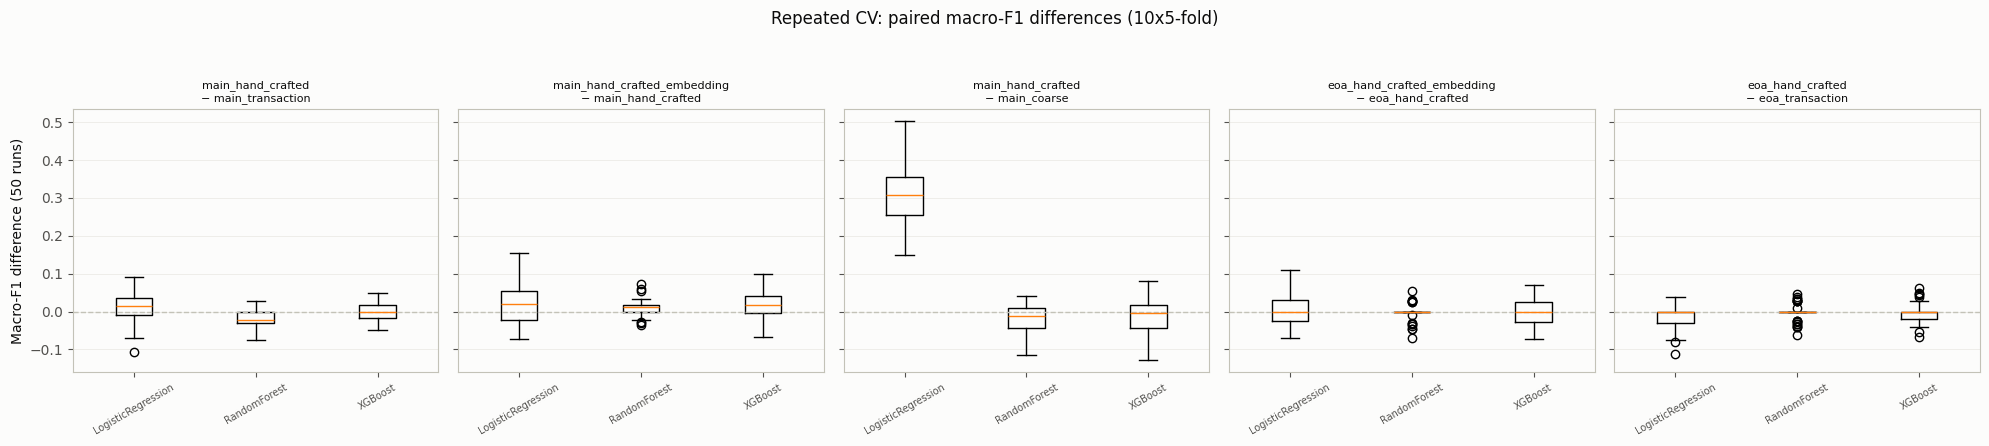

In [6]:
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
                      "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b", "xtick.color": "#52514e",
                      "ytick.color": "#52514e", "grid.color": "#e1e0d9", "font.size": 10})

fig, axes = plt.subplots(1, len(comparisons), figsize=(4 * len(comparisons), 4.5), sharey=True)
for ax, (a_name, b_name) in zip(axes, comparisons):
    box_data = []
    for model_name in MODEL_ORDER:
        a = fold_results[a_name][fold_results[a_name].model == model_name].sort_values(["repeat", "fold"])["macro_f1"].values
        b = fold_results[b_name][fold_results[b_name].model == model_name].sort_values(["repeat", "fold"])["macro_f1"].values
        box_data.append(a - b)
    ax.boxplot(box_data, tick_labels=MODEL_ORDER)
    ax.axhline(0, color="#c3c2b7", linestyle="--", linewidth=1)
    ax.set_title(f"{a_name}\n− {b_name}", fontsize=8)
    ax.tick_params(axis="x", rotation=30, labelsize=7)
    ax.grid(axis="y", linewidth=0.6, alpha=0.6)
    ax.set_axisbelow(True)
axes[0].set_ylabel("Macro-F1 difference (50 runs)")
fig.suptitle("Repeated CV: paired macro-F1 differences (10x5-fold)", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.93])
display(fig)
plt.close(fig)

## 5. Repeat-level correction (n=10 independent repeats, not n=50 correlated folds)

In [7]:
# The 5 folds within one repeat share heavily overlapping training sets (each
# fold's training set is 4/5 of the same 436/314 samples), so they are not
# independent observations. Treating all 50 fold-level runs as independent in
# Section 3's paired t-test overstates precision. This aggregates to one
# mean-macro-F1 per repeat first (n=10 genuinely independent observations
# per model), then re-runs the paired comparison -- the statistically
# defensible version of the Section 3 table.

repeat_level_rows = []
for a_name, b_name in comparisons:
    for model_name in MODEL_ORDER:
        a = fold_results[a_name][fold_results[a_name].model == model_name].groupby("repeat")["macro_f1"].mean().sort_index().values
        b = fold_results[b_name][fold_results[b_name].model == model_name].groupby("repeat")["macro_f1"].mean().sort_index().values
        diff = a - b
        n = len(diff)
        mean_diff = diff.mean()
        sem = diff.std(ddof=1) / np.sqrt(n)
        ci_lo, ci_hi = mean_diff - stats.t.ppf(0.975, n - 1) * sem, mean_diff + stats.t.ppf(0.975, n - 1) * sem
        t_stat, p_val = stats.ttest_rel(a, b)
        repeat_level_rows.append({
            "comparison": f"{a_name} vs {b_name}", "model": model_name, "n_independent_repeats": n,
            "mean_diff": mean_diff, "diff_95ci_lo": ci_lo, "diff_95ci_hi": ci_hi,
            "paired_t_stat": t_stat, "paired_p_value": p_val, "pct_repeats_improved": (diff > 0).mean(),
        })

repeat_level_df = pd.DataFrame(repeat_level_rows).round(4)
repeat_level_df.to_csv(OUT_DIR / "repeated_cv_repeat_level_ci.csv", index=False)
print(f"\n=== Repeat-level correction (n=10 independent repeats, avoids fold pseudo-replication) ===")
print(repeat_level_df.to_string(index=False))
print(f"Saved {OUT_DIR / 'repeated_cv_repeat_level_ci.csv'}")

print("\n=== P2 repeated CV complete ===")


=== Repeat-level correction (n=10 independent repeats, avoids fold pseudo-replication) ===
                                      comparison              model  n_independent_repeats  mean_diff  diff_95ci_lo  diff_95ci_hi  paired_t_stat  paired_p_value  pct_repeats_improved
           main_hand_crafted vs main_transaction LogisticRegression                     10     0.0096        0.0013        0.0178         2.6311          0.0273                   0.8
           main_hand_crafted vs main_transaction       RandomForest                     10    -0.0192       -0.0258       -0.0127        -6.6927          0.0001                   0.1
           main_hand_crafted vs main_transaction            XGBoost                     10    -0.0006       -0.0075        0.0064        -0.1860          0.8566                   0.6
main_hand_crafted_embedding vs main_hand_crafted LogisticRegression                     10     0.0211        0.0135        0.0287         6.2668          0.0001                

## Key result tables

In [8]:
display(summary)
display(diff_df)
display(repeat_level_df)

,condition,model,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std
0,eoa_hand_crafted,LogisticRegression,0.9153,0.0401,0.9180,0.0444
1,eoa_hand_crafted,RandomForest,0.9195,0.0488,0.8927,0.0633
2,eoa_hand_crafted,XGBoost,0.9251,0.0527,0.9089,0.0654
3,eoa_hand_crafted_embedding,LogisticRegression,0.9238,0.0397,0.9305,0.0434
4,eoa_hand_crafted_embedding,RandomForest,0.9178,0.0503,0.8854,0.0651
5,eoa_hand_crafted_embedding,XGBoost,0.9226,0.0523,0.9050,0.0686
6,eoa_transaction,LogisticRegression,0.9330,0.0365,0.9230,0.0479
7,eoa_transaction,RandomForest,0.9212,0.0499,0.8942,0.0643
8,eoa_transaction,XGBoost,0.9267,0.0537,0.9108,0.0642
9,main_coarse,LogisticRegression,0.5766,0.0772,0.6277,0.0537


,comparison,model,n_runs,a_mean,a_std,b_mean,b_std,mean_diff,diff_95ci_lo,diff_95ci_hi,paired_t_stat,paired_p_value,pct_runs_improved,pct_runs_diff_over_0.01
0,main_hand_crafted vs main_transaction,LogisticRegression,50,0.8919,0.0430,0.8823,0.0282,0.0096,-0.0008,0.0199,1.8163,0.0754,0.58,0.78
1,main_hand_crafted vs main_transaction,RandomForest,50,0.8911,0.0382,0.9103,0.0353,-0.0192,-0.0257,-0.0128,-5.8374,0.0000,0.10,0.72
2,main_hand_crafted vs main_transaction,XGBoost,50,0.8946,0.0417,0.8952,0.0385,-0.0006,-0.0071,0.0060,-0.1714,0.8646,0.38,0.56
3,main_hand_crafted_embedding vs main_hand_crafted,LogisticRegression,50,0.9130,0.0374,0.8919,0.0430,0.0211,0.0066,0.0356,2.8561,0.0063,0.62,0.90
4,main_hand_crafted_embedding vs main_hand_crafted,RandomForest,50,0.9029,0.0398,0.8911,0.0382,0.0118,0.0063,0.0173,4.2224,0.0001,0.70,0.80
5,main_hand_crafted_embedding vs main_hand_crafted,XGBoost,50,0.9107,0.0396,0.8946,0.0417,0.0161,0.0060,0.0262,3.1208,0.0030,0.58,0.80
6,main_hand_crafted vs main_coarse,LogisticRegression,50,0.8919,0.0430,0.5766,0.0764,0.3153,0.2929,0.3377,27.5398,0.0000,1.00,1.00
7,main_hand_crafted vs main_coarse,RandomForest,50,0.8911,0.0382,0.9102,0.0307,-0.0192,-0.0297,-0.0086,-3.5600,0.0008,0.30,0.84
8,main_hand_crafted vs main_coarse,XGBoost,50,0.8946,0.0417,0.9055,0.0303,-0.0109,-0.0239,0.0021,-1.6459,0.1062,0.40,0.78
9,eoa_hand_crafted_embedding vs eoa_hand_crafted,LogisticRegression,50,0.9238,0.0393,0.9153,0.0397,0.0085,-0.0031,0.0201,1.4345,0.1578,0.48,0.82


,comparison,model,n_independent_repeats,mean_diff,diff_95ci_lo,diff_95ci_hi,paired_t_stat,paired_p_value,pct_repeats_improved
0,main_hand_crafted vs main_transaction,LogisticRegression,10,0.0096,0.0013,0.0178,2.6311,0.0273,0.8
1,main_hand_crafted vs main_transaction,RandomForest,10,-0.0192,-0.0258,-0.0127,-6.6927,0.0001,0.1
2,main_hand_crafted vs main_transaction,XGBoost,10,-0.0006,-0.0075,0.0064,-0.1860,0.8566,0.6
3,main_hand_crafted_embedding vs main_hand_crafted,LogisticRegression,10,0.0211,0.0135,0.0287,6.2668,0.0001,1.0
4,main_hand_crafted_embedding vs main_hand_crafted,RandomForest,10,0.0118,0.0053,0.0182,4.1387,0.0025,1.0
5,main_hand_crafted_embedding vs main_hand_crafted,XGBoost,10,0.0161,0.0091,0.0231,5.1970,0.0006,1.0
6,main_hand_crafted vs main_coarse,LogisticRegression,10,0.3153,0.2913,0.3393,29.7707,0.0000,1.0
7,main_hand_crafted vs main_coarse,RandomForest,10,-0.0192,-0.0231,-0.0152,-11.0477,0.0000,0.0
8,main_hand_crafted vs main_coarse,XGBoost,10,-0.0109,-0.0167,-0.0050,-4.2151,0.0023,0.1
9,eoa_hand_crafted_embedding vs eoa_hand_crafted,LogisticRegression,10,0.0085,-0.0002,0.0172,2.1982,0.0555,0.8


## Interpretation

Repeat-level differences are the primary statistical evidence. Fold-level rows remain available as raw results for auditing and reconstruction.